# LLM Architectures Explained: RNNs, LSTMs & GRUs (Part 3)

Code from the article [LLM Architectures Explained: RNNs, LSTMs & GRUs (Part 3)](https://medium.com/@vipra_singh/llm-architectures-explained-rnn-lstm-grus-part-3-c5e1cbfeda1d), in the order it appears there. Every code cell below was run from top to bottom; the outputs are from that run. Cells marked **Added for this repository** are not in the article: they download data or set things up so the notebook runs on a fresh machine.

**Added for this repository:** the Keras examples in section 5 need `keras`, which the article doesn't import. Here Keras 3 runs on the PyTorch backend, so TensorFlow isn't required.

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'   # run Keras on PyTorch, so TensorFlow isn't needed
import keras
print('Keras', keras.__version__, 'with the', keras.backend.backend(), 'backend')

Keras 3.15.1 with the torch backend


## 3.1 Unfolding RNNs in Time

Excerpt from the class defined in full further down (shown here as text; the full class is what runs):

```python
self.weights_ih = np.random.randn(input_size, hidden_size) * 0.01
```

Excerpt from the class defined in full further down (shown here as text; the full class is what runs):

```python
for i, x in enumerate(inputs):
    x = x.reshape(1, -1)  # Ensure x is a row vector
    h = np.tanh(np.dot(x, self.weights_ih) + np.dot(h, self.weights_hh) + self.bias_h)
    self.last_hs[i + 1] = h
```

## 3.2.1 Forward Pass

Excerpt from the class defined in full further down (shown here as text; the full class is what runs):

```python
h = np.zeros((1, self.hidden_size))
```

Excerpt from the class defined in full further down (shown here as text; the full class is what runs):

```python
self.weights_ih = np.random.randn(input_size, hidden_size) * 0.01
self.weights_hh = np.random.randn(hidden_size, hidden_size) * 0.01
self.weights_ho = np.random.randn(hidden_size, output_size) * 0.01
```

## 5.1 Proper Weight Initialization

```
where  fanavg = ( fanin + fanout ) / 2
```

In [2]:
keras.layers.Dense(25, activation = "relu", kernel_initializer="he_normal")

<Dense name=dense, built=False>

In [3]:
keras.layers.Dense(25, activation = "relu", kernel_initializer="he_uniform")

<Dense name=dense_1, built=False>

In [4]:
he_avg_init = keras.initializers.VarianceScaling(scale=2., mode='fan_avg', distribution='uniform')
keras.layers.Dense(20, activation="sigmoid", kernel_initializer=he_avg_init)

<Dense name=dense_2, built=False>

## 5.2 Using Non-saturating Activation Functions

```
Relu(z) = max(0,z)
```

```
LeakyReLUα(z) = max(αz, z)
```

## 5.3 Batch Normalization

In [5]:
model = keras.models.Sequential([keras.layers.Flatten(input_shape=[28, 28]),keras.layers.BatchNormalization(),keras.layers.Dense(300, activation="relu"),keras.layers.BatchNormalization(),keras.layers.Dense(100, activation="relu"),keras.layers.BatchNormalization(),keras.layers.Dense(10, activation="softmax")])

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 784)            │         3,136 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 300)            │         1,200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 271,346 (1.04 MB)

Trainable params: 268,978 (1.03 MB)

Non-trainable params: 2,368 (9.25 KB)

## 5.4 Gradient Clipping

In [7]:
optimizer = keras.optimizers.SGD(clipvalue = 1.0)

In [8]:
optimizer = keras.optimizers.SGD(clipnorm = 1.0)

## 6.1 Defining the RNN Class

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class RNN:
    def __init__(self, input_size, hidden_size, output_size, init_method="random"):
        self.weights_ih, self.weights_hh, self.weights_ho = self.initialize_weights(input_size, hidden_size, output_size, init_method)
        self.bias_h = np.zeros((1, hidden_size))
        self.bias_o = np.zeros((1, output_size))
        self.hidden_size = hidden_size

    def initialize_weights(self, input_size, hidden_size, output_size, method):
        if method == "random":
            weights_ih = np.random.randn(input_size, hidden_size) * 0.01
            weights_hh = np.random.randn(hidden_size, hidden_size) * 0.01
            weights_ho = np.random.randn(hidden_size, output_size) * 0.01
        elif method == "xavier":
            weights_ih = np.random.randn(input_size, hidden_size) * np.sqrt(2 / (input_size + hidden_size))
            weights_hh = np.random.randn(hidden_size, hidden_size) * np.sqrt(2 / (hidden_size + hidden_size))
            weights_ho = np.random.randn(hidden_size, output_size) * np.sqrt(2 / (hidden_size + output_size))
        elif method == "he":
            weights_ih = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
            weights_hh = np.random.randn(hidden_size, hidden_size) * np.sqrt(2 / hidden_size)
            weights_ho = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
        else:
            raise ValueError("Invalid initialization method")
        return weights_ih, weights_hh, weights_ho


    def forward(self, inputs):
        h = np.zeros((1, self.hidden_size))
        self.last_inputs = inputs
        self.last_hs = {0: h}

        for i, x in enumerate(inputs):
            x = x.reshape(1, -1)  # Ensure x is a row vector
            h = np.tanh(np.dot(x, self.weights_ih) + np.dot(h, self.weights_hh) + self.bias_h)
            self.last_hs[i + 1] = h

        y = np.dot(h, self.weights_ho) + self.bias_o
        self.last_outputs = y
        return y

    def backprop(self, d_y, learning_rate, clip_value=1):
        n = len(self.last_inputs)

        d_y_pred = (self.last_outputs - d_y) / d_y.size
        d_Whh = np.zeros_like(self.weights_hh)
        d_Wxh = np.zeros_like(self.weights_ih)
        d_Why = np.zeros_like(self.weights_ho)
        d_bh = np.zeros_like(self.bias_h)
        d_by = np.zeros_like(self.bias_o)
        d_h = np.dot(d_y_pred, self.weights_ho.T)
        d_Why = np.dot(self.last_hs[n].T, d_y_pred)  # output-layer gradients
        d_by = d_y_pred.copy()

        for t in reversed(range(1, n + 1)):
            d_h_raw = (1 - self.last_hs[t] ** 2) * d_h
            d_bh += d_h_raw
            d_Whh += np.dot(self.last_hs[t - 1].T, d_h_raw)
            d_Wxh += np.dot(self.last_inputs[t - 1].reshape(1, -1).T, d_h_raw)
            d_h = np.dot(d_h_raw, self.weights_hh.T)

        for d in [d_Wxh, d_Whh, d_Why, d_bh, d_by]:
            np.clip(d, -clip_value, clip_value, out=d)

        self.weights_ih -= learning_rate * d_Wxh
        self.weights_hh -= learning_rate * d_Whh
        self.weights_ho -= learning_rate * d_Why
        self.bias_h -= learning_rate * d_bh
        self.bias_o -= learning_rate * d_by

## 6.2 Early Stopping Mechanism

In [10]:
class EarlyStopping:
    def __init__(self, patience=7, verbose=False, delta=0):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.delta = delta

    def __call__(self, val_loss):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score

        elif score < self.best_score + self.delta:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.counter = 0

## 6.3 RNN Trainer Class

In [11]:
class RNNTrainer:
    def __init__(self, model, loss_func='mse'):
        self.model = model
        self.loss_func = loss_func
        self.train_loss = []
        self.val_loss = []

    def calculate_loss(self, y_true, y_pred):
        if self.loss_func == 'mse':
            return np.mean((y_pred - y_true)**2)

        elif self.loss_func == 'log_loss':
            return -np.mean(y_true*np.log(y_pred) + (1-y_true)*np.log(1-y_pred))

        elif self.loss_func == 'categorical_crossentropy':
            return -np.mean(y_true*np.log(y_pred))

        else:
            raise ValueError('Invalid loss function')

    def train(self, train_data, train_labels, val_data, val_labels, epochs, learning_rate, early_stopping=True, patience=10, clip_value=1):
        if early_stopping:
            early_stopping = EarlyStopping(patience=patience, verbose=True)
        for epoch in range(epochs):
            for X_train, y_train in zip(train_data, train_labels):
                outputs = self.model.forward(X_train)
                self.model.backprop(y_train, learning_rate, clip_value)
                train_loss = self.calculate_loss(y_train, outputs)
                self.train_loss.append(train_loss)

            val_loss_epoch = []
            for X_val, y_val in zip(val_data, val_labels):
                val_outputs = self.model.forward(X_val)
                val_loss = self.calculate_loss(y_val, val_outputs)
                val_loss_epoch.append(val_loss)

            val_loss = np.mean(val_loss_epoch)
            self.val_loss.append(val_loss)

            if early_stopping:
                early_stopping(val_loss)

                if early_stopping.early_stop:
                    print(f"Early stopping at epoch {epoch} | Best validation loss = {-early_stopping.best_score:.3f}")
                    break

            if epoch % 10 == 0:
                print(f'Epoch {epoch}: Train loss = {train_loss:.4f}, Validation loss = {val_loss:.4f}')

    def plot_gradients(self):
        for i, gradients in enumerate(zip(*self.gradients)):
            plt.plot(gradients, label=f'Neuron {i}')

        plt.xlabel('Time step')
        plt.ylabel('Gradient')
        plt.title('Gradients for each neuron over time')
        plt.legend()
        plt.show()

## 6.4 Data Loading and Preprocessing

In [12]:
class TimeSeriesDataset:
    def __init__(self, url, look_back=1, train_size=0.67):
        self.url = url
        self.look_back = look_back
        self.train_size = train_size

    def load_data(self):
        df = pd.read_csv(self.url, usecols=[1])
        df = self.MinMaxScaler(df.values)  # Convert DataFrame to numpy array
        train_size = int(len(df) * self.train_size)
        train, test = df[0:train_size,:], df[train_size:len(df),:]
        return train, test

    def MinMaxScaler(self, data):
        numerator = data - np.min(data, 0)
        denominator = np.max(data, 0) - np.min(data, 0)
        return numerator / (denominator + 1e-7)

    def create_dataset(self, dataset):
        dataX, dataY = [], []
        for i in range(len(dataset)-self.look_back-1):
            a = dataset[i:(i+self.look_back), 0]
            dataX.append(a)
            dataY.append(dataset[i + self.look_back, 0])
        return np.array(dataX), np.array(dataY)

    def get_train_test(self):
        train, test = self.load_data()
        trainX, trainY = self.create_dataset(train)
        testX, testY = self.create_dataset(test)
        return trainX, trainY, testX, testY

In [13]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
dataset = TimeSeriesDataset(url, look_back=1)
trainX, trainY, testX, testY = dataset.get_train_test()

In [14]:
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

## 6.5 Training the RNN

In [15]:
look_back = 1  # same value as in TimeSeriesDataset above
rnn = RNN(look_back, 256, 1, init_method='xavier')
trainer = RNNTrainer(rnn, 'mse')
trainer.train(trainX, trainY, testX, testY, epochs=100, learning_rate=0.0003, early_stopping=True, patience=10, clip_value=1)

Epoch 0: Train loss = 0.0004, Validation loss = 0.0249


Epoch 10: Train loss = 0.0002, Validation loss = 0.0130


Epoch 20: Train loss = 0.0001, Validation loss = 0.0104


Epoch 30: Train loss = 0.0006, Validation loss = 0.0095


Epoch 40: Train loss = 0.0011, Validation loss = 0.0091


Epoch 50: Train loss = 0.0014, Validation loss = 0.0090


Epoch 60: Train loss = 0.0017, Validation loss = 0.0090


Epoch 70: Train loss = 0.0018, Validation loss = 0.0090


Epoch 80: Train loss = 0.0019, Validation loss = 0.0089


Epoch 90: Train loss = 0.0019, Validation loss = 0.0089


## 11.1 Imports and Initial Setup

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class WeightInitializer:
    def __init__(self, method='random'):
        self.method = method

    def initialize(self, shape):
        if self.method == 'random':
            return np.random.randn(*shape)
        elif self.method == 'xavier':
            return np.random.randn(*shape) / np.sqrt(shape[0])
        elif self.method == 'he':
            return np.random.randn(*shape) * np.sqrt(2 / shape[0])
        elif self.method == 'uniform':
            return np.random.uniform(-1, 1, shape)
        else:
            raise ValueError(f'Unknown initialization method: {self.method}')

In [17]:
class PlotManager:
    def __init__(self):
        self.fig, self.ax = plt.subplots(figsize=(6, 4))

    def plot_losses(self, train_losses, val_losses):
        self.ax.plot(train_losses, label='Training Loss')
        self.ax.plot(val_losses, label='Validation Loss')
        self.ax.set_title('Training and Validation Losses')
        self.ax.set_xlabel('Epoch')
        self.ax.set_ylabel('Loss')
        self.ax.legend()

    def show_plots(self):
        plt.tight_layout()
        plt.show()

In [18]:
class EarlyStopping:
    """
    Early stopping to stop the training when the loss does not improve after

    Args:
    -----
        patience (int): Number of epochs to wait before stopping the training.
        verbose (bool): If True, prints a message for each epoch where the loss
                        does not improve.
        delta (float): Minimum change in the monitored quantity to qualify as an improvement.
    """
    def __init__(self, patience=7, verbose=False, delta=0):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.delta = delta

    def __call__(self, val_loss):
        """
        Determines if the model should stop training.

        Args:
            val_loss (float): The loss of the model on the validation set.
        """
        score = -val_loss

        if self.best_score is None:
            self.best_score = score

        elif score < self.best_score + self.delta:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.counter = 0

## 11.2 LSTM Class

In [19]:
class LSTM:
    """
    Long Short-Term Memory (LSTM) network.

    Parameters:
    - input_size: int, dimensionality of input space
    - hidden_size: int, number of LSTM units
    - output_size: int, dimensionality of output space
    - init_method: str, weight initialization method (default: 'xavier')
    """
    def __init__(self, input_size, hidden_size, output_size, init_method='xavier'):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.weight_initializer = WeightInitializer(method=init_method)

        # Initialize weights
        self.wf = self.weight_initializer.initialize((hidden_size, hidden_size + input_size))
        self.wi = self.weight_initializer.initialize((hidden_size, hidden_size + input_size))
        self.wo = self.weight_initializer.initialize((hidden_size, hidden_size + input_size))
        self.wc = self.weight_initializer.initialize((hidden_size, hidden_size + input_size))

        # Initialize biases
        self.bf = np.zeros((hidden_size, 1))
        self.bi = np.zeros((hidden_size, 1))
        self.bo = np.zeros((hidden_size, 1))
        self.bc = np.zeros((hidden_size, 1))

        # Initialize output layer weights and biases
        self.why = self.weight_initializer.initialize((output_size, hidden_size))
        self.by = np.zeros((output_size, 1))

    @staticmethod
    def sigmoid(z):
        """
        Sigmoid activation function.

        Parameters:
        - z: np.ndarray, input to the activation function

        Returns:
        - np.ndarray, output of the activation function
        """
        return 1 / (1 + np.exp(-z))

    @staticmethod
    def dsigmoid(y):
        """
        Derivative of the sigmoid activation function.

        Parameters:
        - y: np.ndarray, output of the sigmoid activation function

        Returns:
        - np.ndarray, derivative of the sigmoid function
        """
        return y * (1 - y)

    @staticmethod
    def dtanh(y):
        """
        Derivative of the hyperbolic tangent activation function.

        Parameters:
        - y: np.ndarray, output of the hyperbolic tangent activation function

        Returns:
        - np.ndarray, derivative of the hyperbolic tangent function
        """
        return 1 - y * y

    def forward(self, x):
        """
        Forward pass through the LSTM network.

        Parameters:
        - x: np.ndarray, input to the network

        Returns:
        - np.ndarray, output of the network
        - list, caches containing intermediate values for backpropagation
        """
        caches = []
        h_prev = np.zeros((self.hidden_size, 1))
        c_prev = np.zeros((self.hidden_size, 1))
        h = h_prev
        c = c_prev

        for t in range(x.shape[0]):
            x_t = x[t].reshape(-1, 1)
            combined = np.vstack((h_prev, x_t))

            f = self.sigmoid(np.dot(self.wf, combined) + self.bf)
            i = self.sigmoid(np.dot(self.wi, combined) + self.bi)
            o = self.sigmoid(np.dot(self.wo, combined) + self.bo)
            c_ = np.tanh(np.dot(self.wc, combined) + self.bc)

            c = f * c_prev + i * c_
            h = o * np.tanh(c)

            cache = (h_prev, c_prev, f, i, o, c_, x_t, combined, c, h)
            caches.append(cache)

            h_prev, c_prev = h, c

        y = np.dot(self.why, h) + self.by
        return y, caches

    def backward(self, dy, caches, clip_value=1.0):
        """
        Backward pass through the LSTM network.

        Parameters:
        - dy: np.ndarray, gradient of the loss with respect to the output
        - caches: list, caches from the forward pass
        - clip_value: float, value to clip gradients to (default: 1.0)

        Returns:
        - tuple, gradients of the loss with respect to the parameters
        """
        dWf, dWi, dWo, dWc = [np.zeros_like(w) for w in (self.wf, self.wi, self.wo, self.wc)]
        dbf, dbi, dbo, dbc = [np.zeros_like(b) for b in (self.bf, self.bi, self.bo, self.bc)]
        dWhy = np.zeros_like(self.why)
        dby = np.zeros_like(self.by)

        # Ensure dy is reshaped to match output size
        dy = dy.reshape(self.output_size, -1)
        dh_next = np.dot(self.why.T, dy)  # the loss reaches the hidden states only through the last h
        dc_next = np.zeros_like(dh_next)

        for cache in reversed(caches):
            h_prev, c_prev, f, i, o, c_, x_t, combined, c, h = cache

            # Add gradient from next step to current output gradient
            dh = dh_next
            dc = dc_next + (dh * o * self.dtanh(np.tanh(c)))

            df = dc * c_prev * self.dsigmoid(f)
            di = dc * c_ * self.dsigmoid(i)
            do = dh * np.tanh(c) * self.dsigmoid(o)
            dc_ = dc * i * self.dtanh(c_)

            dcombined_f = np.dot(self.wf.T, df)
            dcombined_i = np.dot(self.wi.T, di)
            dcombined_o = np.dot(self.wo.T, do)
            dcombined_c = np.dot(self.wc.T, dc_)

            dcombined = dcombined_f + dcombined_i + dcombined_o + dcombined_c
            dh_next = dcombined[:self.hidden_size]
            dc_next = f * dc

            dWf += np.dot(df, combined.T)
            dWi += np.dot(di, combined.T)
            dWo += np.dot(do, combined.T)
            dWc += np.dot(dc_, combined.T)

            dbf += df.sum(axis=1, keepdims=True)
            dbi += di.sum(axis=1, keepdims=True)
            dbo += do.sum(axis=1, keepdims=True)
            dbc += dc_.sum(axis=1, keepdims=True)

        dWhy += np.dot(dy, caches[-1][-1].T)  # last hidden state h_T
        dby += dy

        gradients = (dWf, dWi, dWo, dWc, dbf, dbi, dbo, dbc, dWhy, dby)

        # Gradient clipping
        for i in range(len(gradients)):
            np.clip(gradients[i], -clip_value, clip_value, out=gradients[i])

        return gradients

    def update_params(self, grads, learning_rate):
        """
        Update the parameters of the network using the gradients.

        Parameters:
        - grads: tuple, gradients of the loss with respect to the parameters
        - learning_rate: float, learning rate
        """
        dWf, dWi, dWo, dWc, dbf, dbi, dbo, dbc, dWhy, dby = grads

        self.wf -= learning_rate * dWf
        self.wi -= learning_rate * dWi
        self.wo -= learning_rate * dWo
        self.wc -= learning_rate * dWc

        self.bf -= learning_rate * dbf
        self.bi -= learning_rate * dbi
        self.bo -= learning_rate * dbo
        self.bc -= learning_rate * dbc

        self.why -= learning_rate * dWhy
        self.by -= learning_rate * dby

## 11.3 Training and Validation

In [20]:
class LSTMTrainer:
    """
    Trainer for the LSTM network.

    Parameters:
    - model: LSTM, the LSTM network to train
    - learning_rate: float, learning rate for the optimizer
    - patience: int, number of epochs to wait before early stopping
    - verbose: bool, whether to print training information
    - delta: float, minimum change in validation loss to qualify as an improvement
    """
    def __init__(self, model, learning_rate=0.01, patience=7, verbose=True, delta=0):
        self.model = model
        self.learning_rate = learning_rate
        self.train_losses = []
        self.val_losses = []
        self.early_stopping = EarlyStopping(patience, verbose, delta)

    def train(self, X_train, y_train, X_val=None, y_val=None, epochs=10, batch_size=1, clip_value=1.0):
        """
        Train the LSTM network.

        Parameters:
        - X_train: np.ndarray, training data
        - y_train: np.ndarray, training labels
        - X_val: np.ndarray, validation data
        - y_val: np.ndarray, validation labels
        - epochs: int, number of training epochs
        - batch_size: int, size of mini-batches
        - clip_value: float, value to clip gradients to
        """
        for epoch in range(epochs):
            epoch_losses = []
            for i in range(0, len(X_train), batch_size):
                batch_X = X_train[i:i + batch_size]
                batch_y = y_train[i:i + batch_size]
                losses = []

                for x, y_true in zip(batch_X, batch_y):
                    y_pred, caches = self.model.forward(x)
                    loss = self.compute_loss(y_pred, y_true.reshape(-1, 1))
                    losses.append(loss)

                    # Backpropagation to get gradients
                    dy = y_pred - y_true.reshape(-1, 1)
                    grads = self.model.backward(dy, caches, clip_value=clip_value)
                    self.model.update_params(grads, self.learning_rate)

                batch_loss = np.mean(losses)
                epoch_losses.append(batch_loss)

            avg_epoch_loss = np.mean(epoch_losses)
            self.train_losses.append(avg_epoch_loss)

            if X_val is not None and y_val is not None:
                val_loss = self.validate(X_val, y_val)
                self.val_losses.append(val_loss)
                print(f'Epoch {epoch + 1}/{epochs} - Loss: {avg_epoch_loss:.5f}, Val Loss: {val_loss:.5f}')

                # Check early stopping condition
                self.early_stopping(val_loss)
                if self.early_stopping.early_stop:
                    print("Early stopping")
                    break
            else:
                print(f'Epoch {epoch + 1}/{epochs} - Loss: {avg_epoch_loss:.5f}')


    def compute_loss(self, y_pred, y_true):
        """
        Compute mean squared error loss.
        """
        return np.mean((y_pred - y_true) ** 2)

    def validate(self, X_val, y_val):
        """
        Validate the model on a separate set of data.
        """
        val_losses = []
        for x, y_true in zip(X_val, y_val):
            y_pred, _ = self.model.forward(x)
            loss = self.compute_loss(y_pred, y_true.reshape(-1, 1))
            val_losses.append(loss)
        return np.mean(val_losses)

## 11.4 Data Preprocessing

In [21]:
class TimeSeriesDataset:
    """
    Dataset class for time series data.

    Parameters:
    - ticker: str, stock ticker symbol
    - start_date: str, start date for data retrieval
    - end_date: str, end date for data retrieval
    - look_back: int, number of previous time steps to include in each sample
    - train_size: float, proportion of data to use for training
    """
    def __init__(self, start_date, end_date, look_back=1, train_size=0.67):
        self.start_date = start_date
        self.end_date = end_date
        self.look_back = look_back
        self.train_size = train_size

    def load_data(self):
        """
        Load stock data.

        Returns:
        - np.ndarray, training data
        - np.ndarray, testing data
        """
        df = pd.read_csv('data/google.csv', parse_dates=['Date'], index_col='Date')
        df = df.sort_index()
        df = df.loc[self.start_date:self.end_date]
        df = df[['Close']].astype(float)  # Use closing price
        df = self.MinMaxScaler(df.values)  # Convert DataFrame to numpy array
        train_size = int(len(df) * self.train_size)
        train, test = df[0:train_size,:], df[train_size:len(df),:]
        return train, test

    def MinMaxScaler(self, data):
        """
        Min-max scaling of the data.

        Parameters:
        - data: np.ndarray, input data
        """
        numerator = data - np.min(data, 0)
        denominator = np.max(data, 0) - np.min(data, 0)
        return numerator / (denominator + 1e-7)

    def create_dataset(self, dataset):
        """
        Create the dataset for time series prediction.

        Parameters:
        - dataset: np.ndarray, input data

        Returns:
        - np.ndarray, input data
        - np.ndarray, output data
        """
        dataX, dataY = [], []
        for i in range(len(dataset)-self.look_back):
            a = dataset[i:(i + self.look_back), 0]
            dataX.append(a)
            dataY.append(dataset[i + self.look_back, 0])
        return np.array(dataX), np.array(dataY)

    def get_train_test(self):
        """
        Get the training and testing data.

        Returns:
        - np.ndarray, training input
        - np.ndarray, training output
        - np.ndarray, testing input
        - np.ndarray, testing output
        """
        train, test = self.load_data()
        trainX, trainY = self.create_dataset(train)
        testX, testY = self.create_dataset(test)
        return trainX, trainY, testX, testY

**Added for this repository:** the article reads `data/google.csv`, a Google (GOOGL) daily price file from Kaggle, which needs a Kaggle account to download. This cell creates the same file (Date and Close columns, 2010–2020) from Yahoo Finance with `yfinance` if it isn't there yet. If you already have the Kaggle file, put it in `data/google.csv` and this cell leaves it alone.

In [22]:
import os
if not os.path.exists('data/google.csv'):
    import yfinance as yf
    os.makedirs('data', exist_ok=True)
    prices = yf.download('GOOGL', start='2010-01-01', end='2021-01-01', auto_adjust=False, progress=False)
    prices.columns = [c[0] if isinstance(c, tuple) else c for c in prices.columns]
    prices.reset_index()[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']].to_csv('data/google.csv', index=False)
print(pd.read_csv('data/google.csv').head(3))

         Date       Open       High        Low      Close     Volume
0  2010-01-04  15.689439  15.753504  15.621622  15.684434   78169752
1  2010-01-05  15.695195  15.711712  15.554054  15.615365  120067812
2  2010-01-06  15.662162  15.662162  15.174174  15.221722  158988852


## 11.5 Model Training

In [23]:
# Instantiate the dataset
dataset = TimeSeriesDataset( '2010-1-1', '2020-12-31', look_back=1)
trainX, trainY, testX, testY = dataset.get_train_test()

In [24]:
# Reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [25]:
look_back = 1  # Number of previous time steps to include in each sample
hidden_size = 256  # Number of LSTM units
output_size = 1  # Dimensionality of the output space

lstm = LSTM(input_size=1, hidden_size=hidden_size, output_size=output_size)

In [26]:
trainer = LSTMTrainer(lstm, learning_rate=1e-3, patience=50, verbose=True, delta=0.001)
trainer.train(trainX, trainY, testX, testY, epochs=1000, batch_size=32)

Epoch 1/1000 - Loss: 0.00044, Val Loss: 0.05419


Epoch 2/1000 - Loss: 0.00206, Val Loss: 0.04681


Epoch 3/1000 - Loss: 0.00179, Val Loss: 0.04044


Epoch 4/1000 - Loss: 0.00155, Val Loss: 0.03494


Epoch 5/1000 - Loss: 0.00134, Val Loss: 0.03018


Epoch 6/1000 - Loss: 0.00116, Val Loss: 0.02608


... (76 outputs left out)

Epoch 83/1000 - Loss: 0.00002, Val Loss: 0.00019


Epoch 84/1000 - Loss: 0.00002, Val Loss: 0.00019


Epoch 85/1000 - Loss: 0.00002, Val Loss: 0.00019


Epoch 86/1000 - Loss: 0.00002, Val Loss: 0.00019
Early stopping


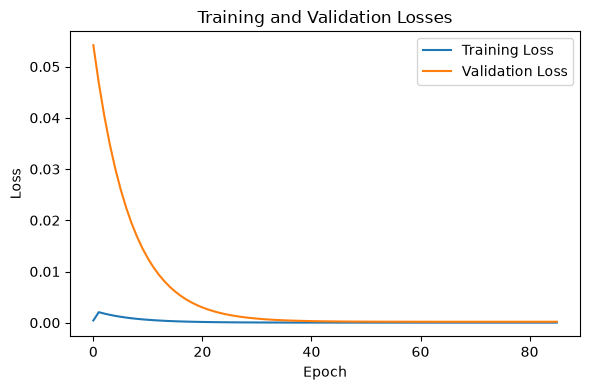

In [27]:
plot_manager = PlotManager()

# Inside your training loop
plot_manager.plot_losses(trainer.train_losses, trainer.val_losses)

# After your training loop
plot_manager.show_plots()

## 14. Implementation of a Simple GRU

In [28]:
import numpy as np

class SimpleGRU:
    def __init__(self, input_size, hidden_size, output_size):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size

        # Initialize weights and biases
        self.W_z = np.random.randn(hidden_size, input_size)
        self.U_z = np.random.randn(hidden_size, hidden_size)
        self.b_z = np.zeros((hidden_size, 1))

        self.W_r = np.random.randn(hidden_size, input_size)
        self.U_r = np.random.randn(hidden_size, hidden_size)
        self.b_r = np.zeros((hidden_size, 1))

        self.W_h = np.random.randn(hidden_size, input_size)
        self.U_h = np.random.randn(hidden_size, hidden_size)
        self.b_h = np.zeros((hidden_size, 1))

        self.W_y = np.random.randn(output_size, hidden_size)
        self.b_y = np.zeros((output_size, 1))

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def tanh(self, x):
        return np.tanh(x)

    def softmax(self, x):
        exp_x = np.exp(x - np.max(x))
        return exp_x / exp_x.sum(axis=0, keepdims=True)

    def forward(self, x):
        T = len(x)
        h = np.zeros((self.hidden_size, 1))
        y_list = []
        self.cache = []  # per-step values needed by backward()

        for t in range(T):
            x_t = x[t].reshape(-1, 1)  # Reshape input to column vector

            # Update gate
            z = self.sigmoid(np.dot(self.W_z, x_t) + np.dot(self.U_z, h) + self.b_z)

            # Reset gate
            r = self.sigmoid(np.dot(self.W_r, x_t) + np.dot(self.U_r, h) + self.b_r)

            # Candidate hidden state
            h_tilde = self.tanh(np.dot(self.W_h, x_t) + np.dot(self.U_h, r * h) + self.b_h)

            # Hidden state update
            h_prev = h
            h = (1 - z) * h_prev + z * h_tilde
            self.cache.append((x_t, h_prev, z, r, h_tilde, h))

            # Output
            y = np.dot(self.W_y, h) + self.b_y
            y_list.append(y)

        return y_list

    def backward(self, x, y_list, target):
        T = len(x)
        dW_z = np.zeros_like(self.W_z)
        dU_z = np.zeros_like(self.U_z)
        db_z = np.zeros_like(self.b_z)

        dW_r = np.zeros_like(self.W_r)
        dU_r = np.zeros_like(self.U_r)
        db_r = np.zeros_like(self.b_r)

        dW_h = np.zeros_like(self.W_h)
        dU_h = np.zeros_like(self.U_h)
        db_h = np.zeros_like(self.b_h)

        dW_y = np.zeros_like(self.W_y)
        db_y = np.zeros_like(self.b_y)

        dh_next = np.zeros((self.hidden_size, 1))

        for t in reversed(range(T)):
            x_t, h_prev, z, r, h_tilde, h = self.cache[t]

            # Output layer
            dy = y_list[t] - target[t].reshape(-1, 1)
            dW_y += np.dot(dy, h.T)
            db_y += dy

            # Gradient reaching h_t (from y_t and from step t+1)
            dh = np.dot(self.W_y.T, dy) + dh_next

            # h_t = (1 - z) * h_prev + z * h_tilde
            dh_tilde = dh * z
            dz = dh * (h_tilde - h_prev)
            dh_prev = dh * (1 - z)

            # Candidate state: h_tilde = tanh(W_h x + U_h (r * h_prev) + b_h)
            da_h = dh_tilde * (1 - h_tilde ** 2)
            dW_h += np.dot(da_h, x_t.T)
            dU_h += np.dot(da_h, (r * h_prev).T)
            db_h += da_h
            drh = np.dot(self.U_h.T, da_h)
            dr = drh * h_prev
            dh_prev += drh * r

            # Reset gate
            da_r = dr * r * (1 - r)
            dW_r += np.dot(da_r, x_t.T)
            dU_r += np.dot(da_r, h_prev.T)
            db_r += da_r
            dh_prev += np.dot(self.U_r.T, da_r)

            # Update gate
            da_z = dz * z * (1 - z)
            dW_z += np.dot(da_z, x_t.T)
            dU_z += np.dot(da_z, h_prev.T)
            db_z += da_z
            dh_prev += np.dot(self.U_z.T, da_z)

            dh_next = dh_prev

        return dW_z, dU_z, db_z, dW_r, dU_r, db_r, dW_h, dU_h, db_h, dW_y, db_y

    def update_parameters(self, dW_z, dU_z, db_z, dW_r, dU_r, db_r, dW_h, dU_h, db_h, dW_y, db_y, learning_rate):
        self.W_z -= learning_rate * dW_z
        self.U_z -= learning_rate * dU_z
        self.b_z -= learning_rate * db_z

        self.W_r -= learning_rate * dW_r
        self.U_r -= learning_rate * dU_r
        self.b_r -= learning_rate * db_r

        self.W_h -= learning_rate * dW_h
        self.U_h -= learning_rate * dU_h
        self.b_h -= learning_rate * db_h

        self.W_y -= learning_rate * dW_y
        self.b_y -= learning_rate * db_y

# Example usage
input_size = 4
hidden_size = 3
output_size = 2

gru = SimpleGRU(input_size, hidden_size, output_size)

# Generate random data
sequence_length = 5
data = [np.random.randn(input_size) for _ in range(sequence_length)]
target = [np.random.randn(output_size) for _ in range(sequence_length)]

# Forward pass
y_list = gru.forward(data)

# Backward pass
dW_z, dU_z, db_z, dW_r, dU_r, db_r, dW_h, dU_h, db_h, dW_y, db_y = gru.backward(data, y_list, target)

# Update weights and biases
learning_rate = 0.1
gru.update_parameters(dW_z, dU_z, db_z, dW_r, dU_r, db_r, dW_h, dU_h, db_h, dW_y, db_y, learning_rate)

**Added for this repository:** the article's GRU example prints nothing; this shows that the forward pass, backward pass and update ran.

In [29]:
print('outputs:', len(y_list), 'time steps, each of shape', y_list[0].shape)
print('gradient shapes:', dW_z.shape, dU_z.shape, dW_y.shape)

outputs: 5 time steps, each of shape (2, 1)
gradient shapes: (3, 4) (3, 3) (2, 3)
